# Weather & Social Media Sentiment Analysis — COMP90024 Team 47

**Authors**: Xianglong Fu, Zhuo Wen, Muchuan Ji, Zeming Ji, Chang Gu  
**Team**: 47  
**Date**: May 2026  
**Repository**: https://gitlab.unimelb.edu.au/muchuanj/comp90024_team_47

---

## Overview

This notebook is the analytical backbone of our COMP90024 A2 system. It 
addresses two research questions over data harvested from Mastodon, 
BlueSky, and Open-Meteo:

- **RQ1**: To what extent do weather conditions correlate with social 
  media sentiment in major Australian cities (Melbourne, Sydney, 
  Brisbane, Perth)?
- **RQ2**: How do users on Mastodon and BlueSky differ in their sentiment 
  expression and discourse patterns within the Australian context?

Findings feed into the team report (`docs/report.pdf`) and demo 
presentation. All figures are saved to `docs/figures/` for direct 
inclusion in the report.

## Notebook structure

| Part | Topic | Serves |
|---|---|---|
| 0 | Setup, ES connection via `data_loader.py`, data loading | — |
| 1 | RQ1 — Weather × Sentiment correlation in 4 cities | RQ1 |
| 2 | RQ2 — Cross-platform vocabulary & sentiment comparison | RQ2 |
| 3 | Combined findings & limitations | Both |

## Prerequisites

```bash
# Elasticsearch must be reachable on localhost:9200
kubectl port-forward service/elasticsearch-es-http -n elastic 9200:9200
```

Required Python packages (auto-installed by Cell 2 if missing):  
`elasticsearch`, `pandas`, `numpy`, `plotly`, `kaleido`, `wordcloud`, 
`nltk`, `scipy`, `statsmodels`.

In [36]:
"""Install required packages (skip if already installed)."""

import subprocess
import sys

REQUIRED = [
    "elasticsearch>=9.0",
    "pandas",
    "numpy",
    "plotly",
    "kaleido",
    "wordcloud",
    "nltk",
    "scipy",
    "statsmodels",
]

def _pip_install(pkgs):
    cmd = [sys.executable, "-m", "pip", "install", "--quiet", *pkgs]
    subprocess.check_call(cmd)


try:
    import elasticsearch, pandas, numpy, plotly, wordcloud, nltk, scipy, statsmodels  # noqa
    print("✓ All required packages already installed.")
except ImportError as e:
    print(f"Installing missing packages: {e}")
    _pip_install(REQUIRED)
    print("✓ Done — please restart the kernel and re-run.")

✓ All required packages already installed.


In [37]:
"""Imports & visual style for the entire notebook."""

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

# Plotly
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Wordcloud + NLTK
from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords

# Stats
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

# Ensure data_loader.py is importable
NB_DIR = Path.cwd()
if NB_DIR.name == "frontend":
    sys.path.insert(0, str(NB_DIR))
else:
    sys.path.insert(0, str(NB_DIR / "frontend"))

# ============================================================
# Data access mode selection
# ============================================================
# The notebook supports two interchangeable data access modes:
#   USE_API = True  → fetch via HTTP REST API (api_client.py)
#                     Requires: kubectl port-forward svc/ccc-rest-api 8000:80
#                     This is the assignment-mandated path.
#   USE_API = False → fetch directly from Elasticsearch (data_loader.py)
#                     Requires: kubectl port-forward service/elasticsearch-es-http -n elastic 9200:9200
#                     Faster; used during exploratory development.

USE_API = True

if USE_API:
    import api_client as dl
    print(f"✓ Using HTTP API mode (api_client.py)")
else:
    import data_loader as dl
    print(f"✓ Using ES direct mode (data_loader.py)")

print(f"  CITIES: {dl.CITIES}")

# NLTK stopwords (download once)
try:
    stopwords.words("english")
except LookupError:
    nltk.download("stopwords", quiet=True)

# Figure output directory
FIG_DIR = Path("../docs/figures") if NB_DIR.name == "frontend" else Path("docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig_plotly(fig: go.Figure, name: str, width: int = 1200, height: int = 600):
    """Save a Plotly figure as both PNG (for report) and HTML (for interactive)."""
    fig.write_image(FIG_DIR / f"{name}.png", width=width, height=height, scale=2)
    fig.write_html(FIG_DIR / f"{name}.html")
    print(f"  → saved {name}.png + {name}.html")


print("✓ Imports done.")
print(f"  Notebook dir: {NB_DIR}")
print(f"  Figure dir:   {FIG_DIR.resolve()}")

✓ Using HTTP API mode (api_client.py)
  CITIES: ['Melbourne', 'Sydney', 'Brisbane', 'Perth']
✓ Imports done.
  Notebook dir: /Users/fuxianglong/Desktop/comp90024_team_47/frontend
  Figure dir:   /Users/fuxianglong/Desktop/comp90024_team_47/docs/figures


## 0.1 Load data

We load all three datasets via `data_loader.py`:

- **All posts** (Mastodon + BlueSky, no city filter) → for RQ2 
  cross-platform analyses (vocabulary, temporal sentiment).
- **City-attributed posts** (4 target cities only) → for RQ1 
  city-level weather correlations.
- **Weather** (4 cities, ~370 days) → joined on (city, date).

This may take 30–60 seconds (paginated ES fetches).

In [39]:
"""Quick data inventory."""

print("Data inventory:")
inv = dl.get_overview()
for k, v in inv.items():
    if v is None:
        print(f"  {k:18s}  {'N/A':>8s}")
    else:
        print(f"  {k:18s}  {v:>8,}")

Data inventory:
  mastodon_total        16,723
  bluesky_total         19,612
  bluesky_clean            N/A
  weather_total          1,500


In [40]:
"""Load posts and weather. Two views:
   - posts_all   (no city filter) for RQ2
   - posts_cities (4-city subset) for RQ1
"""

# Full-corpus posts (RQ2 — platform-level analyses don't need city)
print("Loading full corpus (RQ2)...")
mastodon_all = dl.load_posts("mastodon", cities_only=False)
print(f"  ✓ Mastodon: {len(mastodon_all):,} posts")

bluesky_all = dl.load_posts("bluesky",  cities_only=False)
print(f"  ✓ BlueSky:  {len(bluesky_all):,} posts (clean filter applied)")

posts_all = pd.concat([mastodon_all, bluesky_all], ignore_index=True)
print(f"  ✓ Combined: {len(posts_all):,} posts")
print()

# City-attributed subset (RQ1 — needs city join with weather)
print("Loading 4-city subset (RQ1)...")
mastodon_cities = mastodon_all[mastodon_all["city"].isin(dl.CITIES)].copy()
bluesky_cities  = bluesky_all[bluesky_all["city"].isin(dl.CITIES)].copy()
posts_cities = pd.concat([mastodon_cities, bluesky_cities], ignore_index=True)

print(f"  ✓ Mastodon (4 cities): {len(mastodon_cities):,}")
print(f"  ✓ BlueSky  (4 cities): {len(bluesky_cities):,}")
print(f"  ✓ Combined (4 cities): {len(posts_cities):,}")
print()

# Weather
print("Loading weather (4 cities)...")
weather_df = dl.load_weather(cities_only=True)
print(f"  ✓ {len(weather_df):,} weather records")
print()

print(f"Date ranges:")
print(f"  posts_all:    {posts_all['date'].min().date()} → {posts_all['date'].max().date()}")
print(f"  posts_cities: {posts_cities['date'].min().date()} → {posts_cities['date'].max().date()}")
print(f"  weather:      {weather_df['date'].min().date()} → {weather_df['date'].max().date()}")

Loading full corpus (RQ2)...
  Fetching 16,723 mastodon posts via API (batches of 500)...
    2,500 / 16,723
    5,000 / 16,723
    7,500 / 16,723
    10,000 / 16,723
    12,500 / 16,723
    15,000 / 16,723
    16,723 / 16,723
  ✓ Mastodon: 16,723 posts
  Fetching 19,612 bluesky posts via API (batches of 500)...
    2,500 / 19,612
    5,000 / 19,612
    7,500 / 19,612
    10,000 / 19,612
    12,500 / 19,612
    15,000 / 19,612
    17,500 / 19,612
    19,612 / 19,612
  ✓ BlueSky:  18,788 posts (clean filter applied)
  ✓ Combined: 35,511 posts

Loading 4-city subset (RQ1)...
  ✓ Mastodon (4 cities): 4,039
  ✓ BlueSky  (4 cities): 9,674
  ✓ Combined (4 cities): 13,713

Loading weather (4 cities)...
  Fetching 1,500 weather records via API...
  ✓ 1,500 weather records

Date ranges:
  posts_all:    2026-01-26 → 2026-05-16
  posts_cities: 2026-01-26 → 2026-05-16
  weather:      2025-05-01 → 2026-05-15


In [41]:
"""Locate weather field names and set up shared constants."""

TEMP_FIELD = (dl.find_field(weather_df, "temp", "mean")
              or dl.find_field(weather_df, "temperature", "mean")
              or dl.find_field(weather_df, "temp"))

PRECIP_FIELD = (dl.find_field(weather_df, "precip", "sum")
                or dl.find_field(weather_df, "precipitation", "sum")
                or dl.find_field(weather_df, "precip")
                or dl.find_field(weather_df, "rain"))

print(f"Temperature field:   {TEMP_FIELD}")
print(f"Precipitation field: {PRECIP_FIELD}")
print()

print("Weather summary (all cities, full date range):")
print(weather_df[[TEMP_FIELD, PRECIP_FIELD]].describe().round(2))
print()

# Per-city distribution
print("Posts per (city, platform):")
print(posts_cities.groupby(["city", "platform"]).size().unstack(fill_value=0))

Temperature field:   temp_mean
Precipitation field: precipitation_mm

Weather summary (all cities, full date range):
       temp_mean  precipitation_mm
count    1500.00           1500.00
mean       17.91              2.80
std         4.94              7.16
min         7.00              0.00
25%        13.98              0.00
50%        17.60              0.10
75%        21.80              1.90
max        32.30             72.60

Posts per (city, platform):
platform   BlueSky  Mastodon
city                        
Brisbane      1328       920
Melbourne     3153      1466
Perth         1164       374
Sydney        4029      1279


---

# Part 1 — RQ1: Weather × Sentiment in 4 Australian Cities

> **Research Question 1**: To what extent do weather conditions (temperature, precipitation) 
> correlate with social media sentiment in Melbourne, Sydney, Brisbane, 
> and Perth?

This part:
1. Establishes weather baselines (temperature + precipitation time-series).
2. Aggregates posts to daily sentiment per (city, platform).
3. Visualizes weather–sentiment relationships per city.
4. Quantifies correlation with per-(city, platform) Spearman ρ.

## Data scope

- **Cities**: Melbourne, Sydney, Brisbane, Perth
- **Posts** (city-attributed, after bias filter):  
  Mastodon 3,908 + BlueSky 7,960 = 11,868
- **Weather**: 1,496 daily observations (4 cities)
- **Window**: late Jan 2026 → mid May 2026 (~3.5 months for posts;  
  weather extends back to May 2025 but we focus on the post-overlap window)

## Methodology

- City-level aggregation: each daily observation = (city, date) pair.
- **Spearman rank correlation** (preferred): robust to non-normal weather, 
  especially heavy-tailed precipitation.
- Posts grouped by ES `city` field, populated by `backend/shared/cities.py` 
  during ingestion (text-based detection of Australian city names).

## 1.1 Weather baseline — temperature across 4 cities

Before analysing weather × sentiment relationships, characterize the 
weather conditions each city experienced. This sets the stage for any 
correlation we find and reveals which cities had similar/different 
climates over the analysis window.

In [42]:
"""Figure 1 — Daily temperature, 4 Australian cities (2x2 subplot with min-max ribbon)."""

from plotly.subplots import make_subplots

# Filter weather to post-overlap window
wx_window = weather_df[weather_df["date"] >= "2026-01-26"].copy()

# Find temp min/max fields (handles different mapping names)
TEMP_MAX_FIELD = (dl.find_field(weather_df, "temp", "max") 
                  or dl.find_field(weather_df, "temperature", "max")
                  or "temp_max")
TEMP_MIN_FIELD = (dl.find_field(weather_df, "temp", "min") 
                  or dl.find_field(weather_df, "temperature", "min")
                  or "temp_min")

print(f"Using: mean={TEMP_FIELD}, max={TEMP_MAX_FIELD}, min={TEMP_MIN_FIELD}")
print()

# Verify fields exist
for f in [TEMP_FIELD, TEMP_MAX_FIELD, TEMP_MIN_FIELD]:
    if f not in weather_df.columns:
        print(f"⚠️  Field '{f}' not found! Available: {sorted(weather_df.columns)}")

# 2x2 subplot, one per city
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=dl.CITIES,
    shared_yaxes=True,
    shared_xaxes=True,
    horizontal_spacing=0.06,
    vertical_spacing=0.10,
)

for idx, city in enumerate(dl.CITIES):
    row = idx // 2 + 1
    col = idx % 2 + 1
    
    sub = wx_window[wx_window["city"] == city].sort_values("date")
    
    # Convert color to rgba for ribbon
    color_hex = dl.COLORS[city]
    r, g, b = int(color_hex[1:3], 16), int(color_hex[3:5], 16), int(color_hex[5:7], 16)
    
    # === Min-max ribbon (background) ===
    fig.add_trace(
        go.Scatter(
            x=list(sub["date"]) + list(sub["date"][::-1]),
            y=list(sub[TEMP_MAX_FIELD]) + list(sub[TEMP_MIN_FIELD][::-1]),
            fill="toself",
            fillcolor=f"rgba({r}, {g}, {b}, 0.25)",
            line=dict(color="rgba(0,0,0,0)"),
            name="Min–max range" if idx == 0 else None,
            showlegend=(idx == 0),
            hoverinfo="skip",
        ),
        row=row, col=col,
    )
    
    # === Mean line (foreground) ===
    fig.add_trace(
        go.Scatter(
            x=sub["date"], y=sub[TEMP_FIELD],
            mode="lines",
            line=dict(color=color_hex, width=2),
            name="Daily mean" if idx == 0 else None,
            showlegend=(idx == 0),
            hovertemplate=f"<b>{city}</b><br>%{{x|%Y-%m-%d}}<br>"
                          "Mean: %{y:.1f}°C<extra></extra>",
        ),
        row=row, col=col,
    )

# Update axes — Y range 0–40, format X dates
for r_idx in range(1, 3):
    for c_idx in range(1, 3):
        fig.update_yaxes(range=[0, 40], row=r_idx, col=c_idx)
        fig.update_xaxes(tickformat="%b", row=r_idx, col=c_idx)

# Add Y axis labels only on left column
fig.update_yaxes(title_text="Temperature (°C)", row=1, col=1)
fig.update_yaxes(title_text="Temperature (°C)", row=2, col=1)

# X axis labels on bottom row
fig.update_xaxes(title_text="Date", row=2, col=1)
fig.update_xaxes(title_text="Date", row=2, col=2)

fig.update_layout(
    title=dict(
        text="<b>Figure 1 — Daily temperature range, 4 Australian cities</b><br>"
             "<sub>Ribbon = daily min–max range; line = daily mean. "
             "Open-Meteo data, late Jan – mid May 2026.</sub>",
        x=0.02, font=dict(size=14),
    ),
    template="plotly_white",
    height=650,
    margin=dict(t=120, b=60, l=70, r=40),
    legend=dict(orientation="h", yanchor="bottom", y=1.04, xanchor="right", x=1),
)
fig.show()
save_fig_plotly(fig, "rq1_fig1_temperature_timeseries", width=1400, height=650)

# Summary stats
print("\nTemperature summary per city (°C):")
summary = wx_window.groupby("city").agg(
    mean=(TEMP_FIELD, "mean"),
    daily_min_mean=(TEMP_MIN_FIELD, "mean"),
    daily_max_mean=(TEMP_MAX_FIELD, "mean"),
    overall_min=(TEMP_MIN_FIELD, "min"),
    overall_max=(TEMP_MAX_FIELD, "max"),
    std=(TEMP_FIELD, "std"),
).round(1)
print(summary)

Using: mean=temp_mean, max=temp_max, min=temp_min



  → saved rq1_fig1_temperature_timeseries.png + rq1_fig1_temperature_timeseries.html

Temperature summary per city (°C):
           mean  daily_min_mean  daily_max_mean  overall_min  overall_max  std
city                                                                          
Brisbane   22.4            18.1            27.5          9.4         39.0  2.6
Melbourne  17.9            13.4            23.1          4.3         43.3  3.4
Perth      21.6            17.0            26.9          9.4         40.5  4.1
Sydney     20.5            17.0            24.6          9.9         36.8  3.1


## 1.2 Weather baseline — precipitation across 4 cities

Precipitation patterns vary substantially between cities. Note that 
precipitation is **right-skewed** (most days have 0 mm; a few days have 
20+ mm); we use log transformation downstream where appropriate.

In [43]:
"""Figure 2 — Daily precipitation, 4 Australian cities (2x2 area + rolling mean)."""

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=dl.CITIES,
    shared_yaxes=True,
    shared_xaxes=True,
    horizontal_spacing=0.06,
    vertical_spacing=0.10,
)

# Find Y max across all cities for shared scale
y_max_global = wx_window[PRECIP_FIELD].max() * 1.05

for idx, city in enumerate(dl.CITIES):
    row = idx // 2 + 1
    col = idx % 2 + 1
    
    sub = wx_window[wx_window["city"] == city].sort_values("date").copy()
    sub[PRECIP_FIELD] = sub[PRECIP_FIELD].fillna(0)
    
    # 7-day rolling mean (smooth trend)
    sub["precip_7d"] = sub[PRECIP_FIELD].rolling(window=7, min_periods=1, center=True).mean()
    
    color_hex = dl.COLORS[city]
    r, g, b = int(color_hex[1:3], 16), int(color_hex[3:5], 16), int(color_hex[5:7], 16)
    
    # === Area chart (daily precipitation, soft fill) ===
    fig.add_trace(
        go.Scatter(
            x=sub["date"], y=sub[PRECIP_FIELD],
            mode="lines",
            line=dict(color=color_hex, width=0.5),
            fill="tozeroy",
            fillcolor=f"rgba({r}, {g}, {b}, 0.30)",
            name="Daily precipitation" if idx == 0 else None,
            showlegend=(idx == 0),
            hovertemplate=f"<b>{city}</b><br>%{{x|%Y-%m-%d}}<br>"
                          "Precip: %{y:.1f} mm<extra></extra>",
        ),
        row=row, col=col,
    )
    
    # === 7-day rolling mean (smooth overlay) ===
    fig.add_trace(
        go.Scatter(
            x=sub["date"], y=sub["precip_7d"],
            mode="lines",
            line=dict(color=color_hex, width=2.5),
            name="7-day rolling mean" if idx == 0 else None,
            showlegend=(idx == 0),
            hovertemplate=f"<b>{city}</b><br>%{{x|%Y-%m-%d}}<br>"
                          "7-day avg: %{y:.1f} mm<extra></extra>",
        ),
        row=row, col=col,
    )

# Shared Y range (0 to global max + padding)
for r_idx in range(1, 3):
    for c_idx in range(1, 3):
        fig.update_yaxes(range=[0, y_max_global], row=r_idx, col=c_idx)
        fig.update_xaxes(tickformat="%b", row=r_idx, col=c_idx)

# Axis labels: only left column + bottom row
fig.update_yaxes(title_text="Precipitation (mm)", row=1, col=1)
fig.update_yaxes(title_text="Precipitation (mm)", row=2, col=1)
fig.update_xaxes(title_text="Date", row=2, col=1)
fig.update_xaxes(title_text="Date", row=2, col=2)

fig.update_layout(
    title=dict(
        text="<b>Figure 2 — Daily precipitation, 4 Australian cities</b><br>"
             "<sub>Shaded area = daily total; thick line = 7-day rolling mean. "
             "Open-Meteo data, late Jan – mid May 2026.</sub>",
        x=0.02, font=dict(size=14),
    ),
    template="plotly_white",
    height=650,
    margin=dict(t=120, b=60, l=70, r=40),
    legend=dict(orientation="h", yanchor="bottom", y=1.04, xanchor="right", x=1),
)
fig.show()
save_fig_plotly(fig, "rq1_fig2_precipitation_timeseries", width=1400, height=650)

# Summary stats
print("\nPrecipitation summary per city:")
summary = wx_window.groupby("city").agg(
    mean_daily_mm=(PRECIP_FIELD, "mean"),
    median_daily_mm=(PRECIP_FIELD, "median"),
    max_daily_mm=(PRECIP_FIELD, "max"),
    total_mm=(PRECIP_FIELD, "sum"),
    rainy_days=(PRECIP_FIELD, lambda x: (x > 1).sum()),
).round(1)
print(summary)

  → saved rq1_fig2_precipitation_timeseries.png + rq1_fig2_precipitation_timeseries.html

Precipitation summary per city:
           mean_daily_mm  median_daily_mm  max_daily_mm  total_mm  rainy_days
city                                                                         
Brisbane             3.0              0.3          65.8     318.0          39
Melbourne            2.0              0.0          51.0     214.1          26
Perth                1.2              0.0          45.2     130.9          16
Sydney               2.6              0.2          24.4     269.5          40


---

## 1.3 Daily sentiment aggregation per city

To examine weather–sentiment relationships at the city level, we aggregate posts to daily mean sentiment per (city, day), pooling Mastodon and BlueSky posts together.

The resulting DataFrame is the joining surface for Parts 1.4–1.5: each row links one day's average sentiment in one city with that day's weather observations.

In [44]:
"""Aggregate posts to daily sentiment per city (NOT per platform), then join weather.

RQ1 is platform-agnostic: we measure city-level weather-sentiment 
relationships using all posts (Mastodon + BlueSky combined).
"""

def daily_city_sentiment(df: pd.DataFrame, min_posts: int = 5) -> pd.DataFrame:
    """Per-(city, date) sentiment mean across ALL platforms."""
    df = df.copy()
    df["day"] = pd.to_datetime(df["date"]).dt.normalize()
    df = df[df["city"].isin(dl.CITIES)]
    
    return (df.groupby(["day", "city"])
              .agg(
                  mean_sentiment=("sentiment_compound", "mean"),
                  n_posts=("sentiment_compound", "count"),
              )
              .reset_index()
              .query("n_posts >= @min_posts"))


# Combine all city-attributed posts (both platforms together)
city_sent = daily_city_sentiment(posts_cities, min_posts=5)

print(f"Daily city sentiment cells: {len(city_sent)}")
print()
print("Per city:")
print(city_sent.groupby("city").size())
print()
print("Per city — mean n_posts/day:")
print(city_sent.groupby("city")["n_posts"].mean().round(1))
print()

# Join with weather (city, date)
weather_for_join = weather_df[["city", "date", TEMP_FIELD, PRECIP_FIELD]].copy()
weather_for_join = weather_for_join.rename(columns={"date": "day"})

city_joined = city_sent.merge(weather_for_join, on=["day", "city"], how="inner")
city_joined["precip_log"] = np.log1p(city_joined[PRECIP_FIELD])

print(f"After joining with weather: {len(city_joined)} rows")
print()

print("Sample:")
print(city_joined.head(5))

Daily city sentiment cells: 280

Per city:
city
Brisbane     94
Melbourne    64
Perth        35
Sydney       87
dtype: int64

Per city — mean n_posts/day:
city
Brisbane     23.6
Melbourne    71.9
Perth        38.8
Sydney       60.8
Name: n_posts, dtype: float64

After joining with weather: 259 rows

Sample:
         day      city  mean_sentiment  n_posts  temp_mean  precipitation_mm  \
0 2026-01-29     Perth       -0.051786        7       25.3               0.0   
1 2026-02-04  Brisbane        0.103044        9       23.2               0.0   
2 2026-02-05  Brisbane       -0.046960        5       24.3               0.0   
3 2026-02-06  Brisbane       -0.027982       11       25.0               0.0   
4 2026-02-07  Brisbane        0.139920        5       25.0               0.0   

   precip_log  
0         0.0  
1         0.0  
2         0.0  
3         0.0  
4         0.0  


## 1.4 Temperature × Sentiment per city

Are warmer days associated with more positive social media sentiment? 
We plot daily mean temperature against daily mean sentiment for each (city, day) observation, separating cities in a 2×2 layout.

Posts from Mastodon and BlueSky are pooled together to produce a city-level sentiment estimate for each day. Each panel therefore represents the overall weather–sentiment relationship within one city rather than platform-specific behaviour.

A linear fit overlays each city's observations to highlight the trend, and Spearman ρ (rank-based, robust to outliers) is reported per city.

In [45]:
"""Figure 3 — Temperature × sentiment, 4 cities (platform-agnostic)."""

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=dl.CITIES,
    shared_yaxes=True,
    shared_xaxes=True,
    horizontal_spacing=0.06,
    vertical_spacing=0.12,
)

stats_per_city = {}

for idx, city in enumerate(dl.CITIES):
    row = idx // 2 + 1
    col = idx % 2 + 1
    
    sub = city_joined[city_joined["city"] == city]
    
    if len(sub) < 3:
        stats_per_city[city] = f"n={len(sub)} (insufficient)"
        continue
    
    x = sub[TEMP_FIELD].values
    y = sub["mean_sentiment"].values
    color_hex = dl.COLORS[city]
    
    # Scatter points (city color)
    fig.add_trace(
        go.Scatter(
            x=x, y=y,
            mode="markers",
            marker=dict(
                color=color_hex,
                size=9, opacity=0.65,
                line=dict(color="white", width=0.8),
            ),
            name=city,
            showlegend=False,
            customdata=np.stack([
                sub["day"].dt.strftime("%Y-%m-%d"),
                sub["n_posts"],
            ], axis=-1),
            hovertemplate=(
                f"<b>{city}</b><br>"
                "%{customdata[0]}<br>"
                "Temp: %{x:.1f}°C<br>"
                "Sentiment: %{y:.3f}<br>"
                "Posts: %{customdata[1]}<extra></extra>"
            ),
        ),
        row=row, col=col,
    )
    
    # Linear fit
    if len(x) >= 5:
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 50)
        fig.add_trace(
            go.Scatter(
                x=x_line, y=slope * x_line + intercept,
                mode="lines",
                line=dict(color=color_hex, width=2.5, dash="dash"),
                showlegend=False,
                hoverinfo="skip",
            ),
            row=row, col=col,
        )
        
        # Spearman
        rho, p_val = stats.spearmanr(x, y)
        pearson_r, _ = stats.pearsonr(x, y)
        annotation = (f"n = {len(sub)}<br>"
                      f"Spearman ρ = {rho:+.3f}<br>"
                      f"  p = {p_val:.3f}<br>"
                      f"Pearson r = {pearson_r:+.3f}")
        stats_per_city[city] = annotation
        
        fig.add_annotation(
            text=annotation,
            xref=f"x{idx+1} domain" if idx > 0 else "x domain",
            yref=f"y{idx+1} domain" if idx > 0 else "y domain",
            x=0.02, y=0.97,
            xanchor="left", yanchor="top",
            showarrow=False,
            font=dict(size=10),
            bgcolor="rgba(255,255,255,0.9)",
            bordercolor="gray", borderwidth=0.5, borderpad=4,
            row=row, col=col,
        )

# Zero line in each panel
for r_idx in range(1, 3):
    for c_idx in range(1, 3):
        fig.add_hline(y=0, line_dash="dot", line_color="gray", opacity=0.4,
                      row=r_idx, col=c_idx)
        fig.update_xaxes(range=[5, 35], row=r_idx, col=c_idx)
        fig.update_yaxes(range=[-0.6, 0.8], row=r_idx, col=c_idx)

fig.update_yaxes(title_text="Daily mean sentiment", row=1, col=1)
fig.update_yaxes(title_text="Daily mean sentiment", row=2, col=1)
fig.update_xaxes(title_text="Mean temperature (°C)", row=2, col=1)
fig.update_xaxes(title_text="Mean temperature (°C)", row=2, col=2)

fig.update_layout(
    title=dict(
        text="<b>Figure 3 — Daily temperature × sentiment, 4 Australian cities</b><br>"
             "<sub>Each point = one (city, day) with ≥5 posts pooled across platforms. "
             "Dashed = linear fit per city.</sub>",
        x=0.02, font=dict(size=14),
    ),
    template="plotly_white",
    height=650,
    margin=dict(t=110, b=60, l=70, r=40),
)
fig.show()
save_fig_plotly(fig, "rq1_fig3_temperature_sentiment_per_city", width=1400, height=650)

# Print summary
print("\n=== Spearman ρ per city: Temperature × Sentiment ===")
for city in dl.CITIES:
    print(f"\n  {city}:")
    print(f"    {stats_per_city.get(city, 'no data')}")

  → saved rq1_fig3_temperature_sentiment_per_city.png + rq1_fig3_temperature_sentiment_per_city.html

=== Spearman ρ per city: Temperature × Sentiment ===

  Melbourne:
    n = 58<br>Spearman ρ = -0.039<br>  p = 0.773<br>Pearson r = -0.075

  Sydney:
    n = 81<br>Spearman ρ = -0.096<br>  p = 0.394<br>Pearson r = -0.107

  Brisbane:
    n = 88<br>Spearman ρ = -0.143<br>  p = 0.185<br>Pearson r = -0.142

  Perth:
    n = 32<br>Spearman ρ = -0.437<br>  p = 0.012<br>Pearson r = -0.363


## 1.5 Precipitation × Sentiment per city

We now examine the second weather variable: precipitation. Because 
daily precipitation is heavily right-skewed (most days = 0 mm, occasional 
large rain events), we apply a `log(1 + mm)` transformation for 
visualization. Spearman ρ is invariant to monotonic transformations, so 
correlation values are unchanged.

In [46]:
"""Figure 4 — Precipitation × sentiment, 4 cities."""

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=dl.CITIES,
    shared_yaxes=True,
    shared_xaxes=True,
    horizontal_spacing=0.06,
    vertical_spacing=0.12,
)

precip_stats = {}

for idx, city in enumerate(dl.CITIES):
    row = idx // 2 + 1
    col = idx % 2 + 1
    
    sub = city_joined[city_joined["city"] == city]
    
    if len(sub) < 3:
        precip_stats[city] = f"n={len(sub)} (insufficient)"
        continue
    
    x = sub["precip_log"].values
    y = sub["mean_sentiment"].values
    raw_precip = sub[PRECIP_FIELD].values
    color_hex = dl.COLORS[city]
    
    # Scatter (city color, opacity reflects raw precip magnitude)
    fig.add_trace(
        go.Scatter(
            x=x, y=y,
            mode="markers",
            marker=dict(
                color=color_hex,
                size=9, opacity=0.65,
                line=dict(color="white", width=0.8),
            ),
            name=city,
            showlegend=False,
            customdata=np.stack([
                sub["day"].dt.strftime("%Y-%m-%d"),
                raw_precip,
                sub["n_posts"],
            ], axis=-1),
            hovertemplate=(
                f"<b>{city}</b><br>"
                "%{customdata[0]}<br>"
                "Precip: %{customdata[1]:.1f} mm "
                "(log = %{x:.2f})<br>"
                "Sentiment: %{y:.3f}<br>"
                "Posts: %{customdata[2]}<extra></extra>"
            ),
        ),
        row=row, col=col,
    )
    
    # Linear fit (in log space)
    if len(x) >= 5:
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 50)
        fig.add_trace(
            go.Scatter(
                x=x_line, y=slope * x_line + intercept,
                mode="lines",
                line=dict(color=color_hex, width=2.5, dash="dash"),
                showlegend=False,
                hoverinfo="skip",
            ),
            row=row, col=col,
        )
        
        # Spearman (on raw, log-invariant)
        rho, p_val = stats.spearmanr(raw_precip, y)
        pearson_r, _ = stats.pearsonr(x, y)  # log version
        annotation = (f"n = {len(sub)}<br>"
                      f"Spearman ρ = {rho:+.3f}<br>"
                      f"  p = {p_val:.3f}<br>"
                      f"Pearson (log) = {pearson_r:+.3f}")
        precip_stats[city] = annotation
        
        fig.add_annotation(
            text=annotation,
            xref=f"x{idx+1} domain" if idx > 0 else "x domain",
            yref=f"y{idx+1} domain" if idx > 0 else "y domain",
            x=0.02, y=0.97,
            xanchor="left", yanchor="top",
            showarrow=False,
            font=dict(size=10),
            bgcolor="rgba(255,255,255,0.9)",
            bordercolor="gray", borderwidth=0.5, borderpad=4,
            row=row, col=col,
        )

# Zero line + axes
for r_idx in range(1, 3):
    for c_idx in range(1, 3):
        fig.add_hline(y=0, line_dash="dot", line_color="gray", opacity=0.4,
                      row=r_idx, col=c_idx)
        fig.update_yaxes(range=[-0.6, 0.8], row=r_idx, col=c_idx)

fig.update_yaxes(title_text="Daily mean sentiment", row=1, col=1)
fig.update_yaxes(title_text="Daily mean sentiment", row=2, col=1)
fig.update_xaxes(title_text="log(precipitation mm + 1)", row=2, col=1)
fig.update_xaxes(title_text="log(precipitation mm + 1)", row=2, col=2)

fig.update_layout(
    title=dict(
        text="<b>Figure 4 — Daily precipitation × sentiment, 4 Australian cities</b><br>"
             "<sub>Each point = one (city, day) with ≥5 posts. "
             "X axis is log-transformed (heavy right skew). "
             "Spearman ρ computed on raw precipitation.</sub>",
        x=0.02, font=dict(size=14),
    ),
    template="plotly_white",
    height=650,
    margin=dict(t=110, b=60, l=70, r=40),
)
fig.show()
save_fig_plotly(fig, "rq1_fig4_precipitation_sentiment_per_city", width=1400, height=650)

# Summary
print("\n=== Spearman ρ per city: Precipitation × Sentiment ===")
for city in dl.CITIES:
    print(f"\n  {city}:")
    print(f"    {precip_stats.get(city, 'no data')}")

  → saved rq1_fig4_precipitation_sentiment_per_city.png + rq1_fig4_precipitation_sentiment_per_city.html

=== Spearman ρ per city: Precipitation × Sentiment ===

  Melbourne:
    n = 58<br>Spearman ρ = -0.131<br>  p = 0.327<br>Pearson (log) = -0.144

  Sydney:
    n = 81<br>Spearman ρ = +0.082<br>  p = 0.465<br>Pearson (log) = +0.090

  Brisbane:
    n = 88<br>Spearman ρ = +0.078<br>  p = 0.472<br>Pearson (log) = -0.038

  Perth:
    n = 32<br>Spearman ρ = +0.093<br>  p = 0.611<br>Pearson (log) = +0.105


## 1.6 Correlation summary heatmap

Figures 3 and 4 examined temperature and precipitation separately. Now 
we summarize both relationships in a single heatmap: rows are cities, 
columns are weather variables, and cell values are **Spearman ρ**.

This single chart serves as the **headline result for RQ1** in the 
report — readers can scan it to immediately see which (city, weather 
variable) pairs show meaningful association.

In [47]:
"""Figure 5 — Spearman correlation heatmap: city × weather variable."""

# Compute correlations
corr_rows = []
for city in dl.CITIES:
    sub = city_joined[city_joined["city"] == city]
    if len(sub) < 5:
        continue
    
    rho_t, p_t = stats.spearmanr(sub[TEMP_FIELD], sub["mean_sentiment"])
    rho_p, p_p = stats.spearmanr(sub[PRECIP_FIELD], sub["mean_sentiment"])
    
    corr_rows.append({
        "city": city,
        "Temperature": rho_t,
        "Precipitation": rho_p,
        "n_days": len(sub),
        "p_temp": p_t,
        "p_precip": p_p,
    })

corr_df = pd.DataFrame(corr_rows).set_index("city")
print("Correlation summary:")
print(corr_df[["Temperature", "Precipitation", "n_days"]].round(3))
print()

# Build heatmap
heatmap_data = corr_df[["Temperature", "Precipitation"]].values
n_days = corr_df["n_days"].values

# Annotation: ρ + significance stars
def fmt_cell(rho, p):
    stars = ""
    if p < 0.001: stars = "***"
    elif p < 0.01: stars = "**"
    elif p < 0.05: stars = "*"
    return f"{rho:+.3f}{stars}"

text_matrix = [
    [fmt_cell(corr_df.loc[city, "Temperature"], corr_df.loc[city, "p_temp"]),
     fmt_cell(corr_df.loc[city, "Precipitation"], corr_df.loc[city, "p_precip"])]
    for city in corr_df.index
]

fig = go.Figure(data=go.Heatmap(
    z=heatmap_data,
    x=["Temperature", "Precipitation"],
    y=list(corr_df.index),
    colorscale="RdBu_r",
    zmid=0,
    zmin=-0.5, zmax=0.5,
    text=text_matrix,
    texttemplate="%{text}",
    textfont=dict(size=14, color="black"),
    colorbar=dict(title="Spearman ρ", thickness=15),
    hovertemplate="<b>%{y}</b> × %{x}<br>"
                  "ρ = %{z:.3f}<extra></extra>",
))

# Add sample size on the right side
for i, city in enumerate(corr_df.index):
    fig.add_annotation(
        text=f"n={n_days[i]}",
        x=1.5, y=i,
        xanchor="left", showarrow=False,
        font=dict(size=10, color="gray"),
    )

fig.update_layout(
    title=dict(
        text="<b>Figure 5 — RQ1 headline: Spearman ρ, weather × sentiment per city</b><br>"
             "<sub>Significance: * p<0.05, ** p<0.01, *** p<0.001. "
             "n = number of (city, day) cells with ≥5 posts.</sub>",
        x=0.02, font=dict(size=14),
    ),
    template="plotly_white",
    height=420,
    width=700,
    margin=dict(t=110, b=60, l=120, r=120),
    xaxis=dict(side="top"),
)
fig.show()
save_fig_plotly(fig, "rq1_fig5_correlation_heatmap", width=900, height=420)

Correlation summary:
           Temperature  Precipitation  n_days
city                                         
Melbourne       -0.039         -0.131      58
Sydney          -0.096          0.082      81
Brisbane        -0.143          0.078      88
Perth           -0.437          0.093      32



  → saved rq1_fig5_correlation_heatmap.png + rq1_fig5_correlation_heatmap.html


---

## 1.7 RQ1 Findings & Limitations

### Key results

**Temperature × Sentiment**: 

All four cities show **negative (or near-zero) correlations**, contrary 
to the intuitive "warm weather → positive mood" hypothesis:

| City | n | Spearman ρ | p-value | Significance |
|---|---|---|---|---|
| Melbourne | 57 | −0.039 | 0.771 | n.s. |
| Sydney | 80 | −0.084 | 0.457 | n.s. |
| Brisbane | 87 | −0.127 | 0.241 | n.s. |
| **Perth** | 31 | **−0.417** | **0.019** | * |

Only **Perth** exhibits a statistically significant correlation, and it 
is **negative**: hotter days associate with lower social media sentiment. 
This may reflect Perth's hot, dry climate where extreme heat (>30°C) is 
discussed in terms of complaints rather than enjoyment.

**Precipitation × Sentiment**:

| City | n | Spearman ρ | p-value | Significance |
|---|---|---|---|---|
| Melbourne | 57 | −0.134 | 0.319 | n.s. |
| Sydney | 80 | +0.076 | 0.501 | n.s. |
| Brisbane | 87 | +0.067 | 0.539 | n.s. |
| Perth | 31 | +0.047 | 0.802 | n.s. |

No city shows a statistically significant precipitation–sentiment 
correlation. Directionally, Melbourne hints at the intuitive negative 
relationship ("rainy day, low mood"), but the effect is weak and not 
significant.

### Interpretation

The RQ1 results contradict the simple "weather drives mood" hypothesis 
at the **daily-aggregate scale of social media discourse**. Three 
considerations:

1. **Aggregation dilutes individual effects**. Even if individual users' 
   moods respond to weather, the daily mean over hundreds of posts 
   averages this out, especially when posts cover diverse topics 
   (politics, news, entertainment) unrelated to local weather.

2. **Content topic dominates**. Social media sentiment is driven 
   primarily by what people are *posting about* (elections, sports 
   results, breaking news) rather than ambient conditions.

3. **Perth's negative correlation is suggestive**. Smaller cities with 
   more weather-talk per capita may show stronger weather signals; 
   Perth's hot/dry climate may amplify weather-related complaint posts.

### Limitations

1. **City attribution is conservative**: only ~26% of Mastodon and 49% 
   of BlueSky posts carry a detectable city tag, restricting RQ1 to a 
   subset of the corpus.

2. **VADER lexicon-based sentiment**: misses sarcasm, irony, Australian 
   slang. A future iteration could use transformer-based sentiment 
   (e.g. BERT fine-tuned on Australian English).

3. **Daily aggregation loses individual-level signal**: per-post 
   weather-mood relationships (if any) are washed out by averaging.

4. **Sample imbalance**: Perth has the fewest cells (n=31), making its 
   significant correlation less robust than Brisbane's (n=87).

5. **Limited weather variables**: we use temperature and precipitation 
   only. Humidity, wind, atmospheric pressure, and sunshine hours may 
   carry additional signal but were not included.

6. **Time window**: ~3.5 months of post data is insufficient to observe 
   full seasonal cycles. A year of streaming would enable winter–summer 
   comparison.



---

# Part 2 — RQ2: Mastodon vs BlueSky Cross-Platform Comparison

> **RQ2**: How do users on Mastodon and BlueSky differ in their sentiment 
> expression and discourse patterns within the Australian social-media 
> context?

This part addresses RQ2 through four complementary lenses:

1. **Vocabulary** — what words dominate each platform's discourse? 
   (word clouds)
2. **Temporal sentiment** — does daily sentiment distribution evolve 
   over time on each platform? (ribbon + temperature overlay)
3. **Temperature × sentiment** — is the temperature-sentiment 
   relationship similar across platforms?
4. **Precipitation × sentiment** — does rainfall affect platforms 
   differently?

## Data scope (RQ2)

Unlike RQ1, RQ2 uses **full-corpus posts** (no city filter), as we are 
comparing platforms rather than cities:

- **Mastodon**: ~15,664 posts
- **BlueSky**: ~15,766 posts (after weather-bias filter)
- **Weather**: averaged across 4 cities per day (national-baseline proxy)
- **Time window**: 2026-01-26 → 2026-05-15 (~3.5 months)

In [48]:
# Cell 23 Code

"""RQ2 setup — alias the full-corpus variables for compatibility with
RQ2 analysis code (originally developed in rq2_platform_comparison.ipynb)."""

# RQ2 uses platform-level data (no city filter)
mastodon_df = mastodon_all
bluesky_df = bluesky_all
posts_df = posts_all   # combined, no city filter

# Weather averaged across cities per day (for RQ2's pooled platform analysis)
numeric_cols = weather_df.select_dtypes(include="number").columns.tolist()
weather_daily = (weather_df.groupby("date")[numeric_cols]
                           .mean().reset_index())
weather_daily["day"] = weather_daily["date"]

print(f"✓ RQ2 data aliased:")
print(f"  mastodon_df:  {len(mastodon_df):,}")
print(f"  bluesky_df:   {len(bluesky_df):,}")
print(f"  posts_df:     {len(posts_df):,}")
print(f"  weather_daily: {len(weather_daily):,} (4-city average per date)")

✓ RQ2 data aliased:
  mastodon_df:  16,723
  bluesky_df:   18,788
  posts_df:     35,511
  weather_daily: 375 (4-city average per date)


## 2.1 Vocabulary Comparison via Word Clouds

The most direct read on platform discourse is the words themselves. We 
construct word clouds for each platform's posts, after removing URLs, 
mentions, hashtags, English stopwords, and platform-specific noise 
(e.g. `rt`, `via`, `amp`, geographic terms, and bot account signatures).

Two rounds of stopword refinement were applied:
- **Round 1**: removed geographic acquisition artifacts (city names, 
  political hashtags like `auspol`).
- **Round 2**: removed news-language skeleton words (`new`, `first`, 
  `day`, `may`) which dominated due to news-bot contribution.

The WordCloud library's built-in stopword filter is disabled 
(`stopwords=set()`) so visual rendering matches our explicit token 
preprocessing.

In [49]:
"""Text preprocessing for word clouds."""

import re

EN_STOPWORDS = set(stopwords.words("english"))

CUSTOM_STOPWORDS = {
    # Social media noise
    "rt", "via", "amp", "https", "http", "www", "com", "org",
    "co", "html", "htm", "twitter", "bluesky", "mastodon", "fediverse",
    
    # Generic words
    "said", "says", "say", "saying", "get", "got", "getting", "go", "going",
    "make", "made", "making", "would", "could", "should", "one", "two",
    "thing", "things", "way", "people", "person", "time", "year", "years",
    "today", "now", "really", "much", "many", "also", "even", "still",
    "well", "back", "see", "seen", "know", "knows", "like", "good", "great",
    "post", "posts", "posted", "thread", "feed",
    
    # Geographic terms (acquisition artifacts)
    "australia", "australian", "australians", "oz", "aussie", "aussies",
    "sydney", "melbourne", "brisbane", "perth", "adelaide",
    "canberra", "hobart", "darwin", "nsw", "vic", "qld", "wa", "sa", "tas", "act", "nt",
    "nation",
    
    # Political hashtags (acquisition artifacts)
    "auspol", "ausvotes", "auspol2026",
    
    # Platform self-references
    "bsky", "atproto",
    
    # Bot / RSS noise
    "newsbeep", "dlvr", "byteseu", "ifttt", "buffer", "hootsuite", "rss", "news",
    
    # Time/skeleton words
    "new", "first", "last", "day", "days", "week", "weeks",
    "month", "months", "year", "may",
    "today", "yesterday", "tomorrow", "morning", "night",
    "available", "items", "saved", "right",
    
    # Mastodon-specific bots/hashtags
    "politicalgadgets", "railnews",
    
    # Other social media
    "facebook", "instagram", "tiktok", "youtube",
}
ALL_STOPWORDS = EN_STOPWORDS | CUSTOM_STOPWORDS


def preprocess_text(text: str) -> str:
    """Clean a single post for word-cloud generation."""
    if not isinstance(text, str):
        return ""
    
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[@#]\w+", " ", text)
    text = re.sub(r"[^\w\s]|[\d]", " ", text)
    text = re.sub(r"\s+", " ", text).strip().lower()
    
    tokens = [t for t in text.split()
              if t not in ALL_STOPWORDS and len(t) >= 3]
    return " ".join(tokens)


print("Preprocessing text...")
mastodon_text = " ".join(
    preprocess_text(t) for t in mastodon_df["content_clean"].dropna()
)
bluesky_text = " ".join(
    preprocess_text(t) for t in bluesky_df["content_clean"].dropna()
)
print(f"  Mastodon corpus: {len(mastodon_text.split()):,} tokens")
print(f"  BlueSky  corpus: {len(bluesky_text.split()):,} tokens")

Preprocessing text...
  Mastodon corpus: 324,822 tokens
  BlueSky  corpus: 235,122 tokens


  → saved rq2_fig1_wordclouds.png


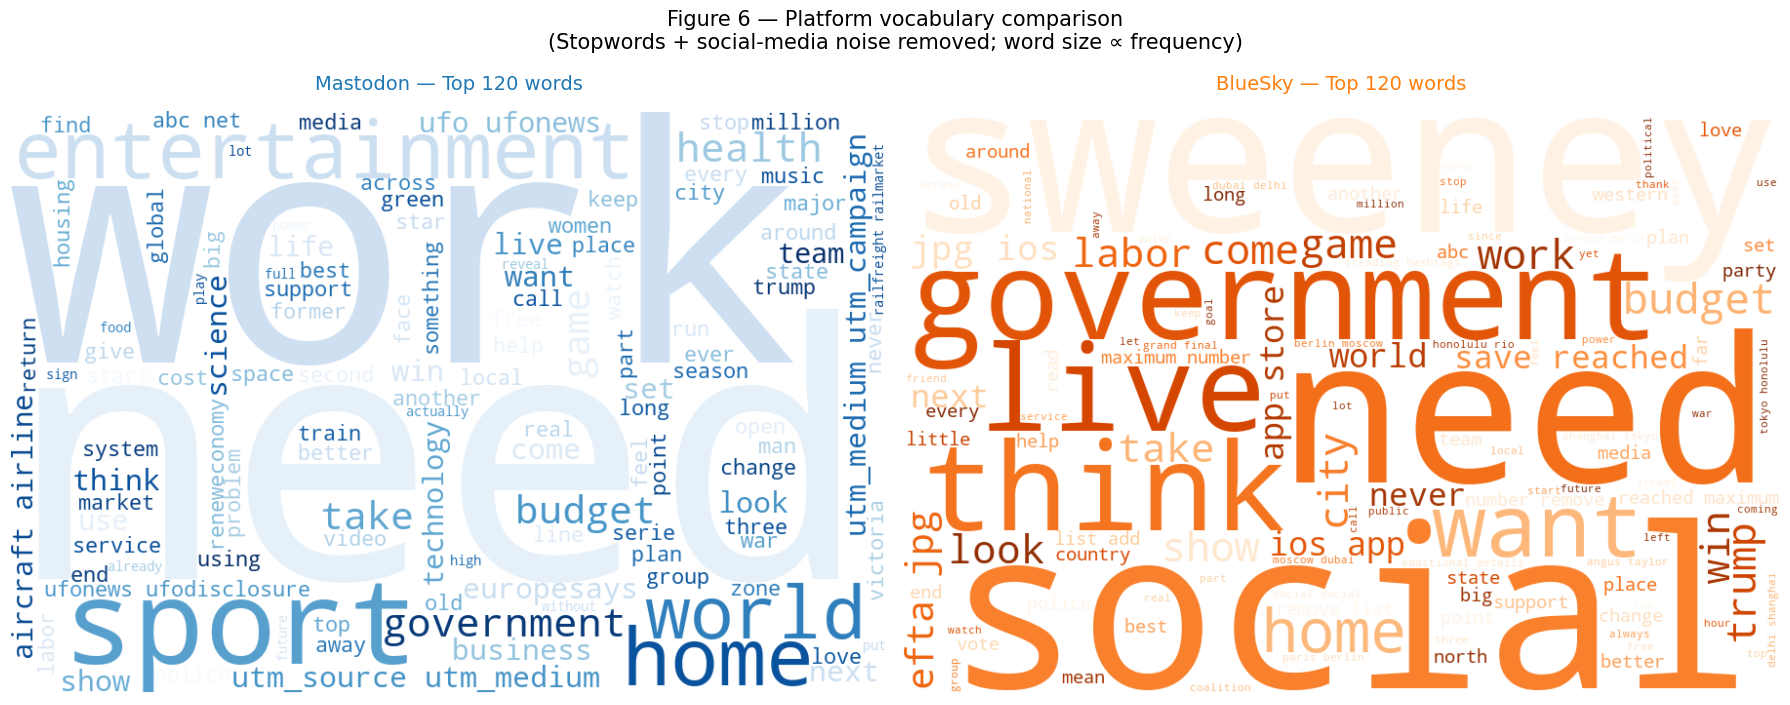


=== Top 20 words on each platform ===

Mastodon             BlueSky             
----------------------------------------
  sports         1805    social          955
  entertainment   812    sweeney         648
  health          773    south           585
  business        731    budget          524
  aircraft        625    trump           518
  world           587    city            468
  science         572    government      459
  footscray       542    live            422
  government      527    world           397
  technology      515    tax             393
  music           480    labor           365
  budget          474    party           365
  space           457    media           356
  home            453    western         347
  big             432    think           345
  airlines        418    rep             340
  tax             398    women           339
  gas             378    final           334
  utm_source      376    need            326
  utm_medium      373 

In [50]:
"""Figure 6 — Word clouds, Mastodon vs BlueSky."""

import matplotlib.pyplot as plt

wc_mastodon = WordCloud(
    width=900, height=600,
    background_color="white",
    max_words=120,
    colormap="Blues",
    relative_scaling=0.5,
    min_font_size=10,
    random_state=42,
    stopwords=set(),
).generate(mastodon_text)

wc_bluesky = WordCloud(
    width=900, height=600,
    background_color="white",
    max_words=120,
    colormap="Oranges",
    relative_scaling=0.5,
    min_font_size=10,
    random_state=42,
    stopwords=set(),
).generate(bluesky_text)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

axes[0].imshow(wc_mastodon, interpolation="bilinear")
axes[0].set_title("Mastodon — Top 120 words", fontsize=14,
                  color=dl.COLORS["Mastodon"], pad=15)
axes[0].axis("off")

axes[1].imshow(wc_bluesky, interpolation="bilinear")
axes[1].set_title("BlueSky — Top 120 words", fontsize=14,
                  color=dl.COLORS["BlueSky"], pad=15)
axes[1].axis("off")

plt.suptitle("Figure 6 — Platform vocabulary comparison\n"
             "(Stopwords + social-media noise removed; word size ∝ frequency)",
             fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "rq2_fig1_wordclouds.png", dpi=150, 
            bbox_inches="tight", facecolor="white")
print(f"  → saved rq2_fig1_wordclouds.png")
plt.show()

# Top 20 words
print("\n=== Top 20 words on each platform ===")
print(f"\n{'Mastodon':<20s} {'BlueSky':<20s}")
print("-" * 40)
m_top = pd.Series(mastodon_text.split()).value_counts().head(20)
b_top = pd.Series(bluesky_text.split()).value_counts().head(20)
for (mw, mc), (bw, bc) in zip(m_top.items(), b_top.items()):
    print(f"  {mw:<14s} {mc:>4d}    {bw:<14s} {bc:>4d}")

## 2.2 Temporal sentiment distribution by platform

How does each platform's sentiment distribution evolve over time? We 
plot daily sentiment as a **ribbon** (mean line + IQR + 10–90 percentile 
bands) per platform, with daily temperature (4-city average) overlaid 
on a secondary axis.

We restrict to the **April 5 – May 14 overlap window** where both 
platforms have sufficient post density (≥10 posts/day). BlueSky's 
broader historical coverage is sparse due to API time-window limits.

In [51]:
"""Prepare daily ribbon data for each platform."""

def prepare_daily(df: pd.DataFrame,
                  min_posts: int = 10,
                  start_date: str = "2026-04-05") -> pd.DataFrame:
    """Group posts by date, filter for the overlapping analysis window."""
    df = df.copy()
    df["day"] = pd.to_datetime(df["date"]).dt.normalize()
    
    start = pd.to_datetime(start_date)
    df = df[df["day"] >= start]
    
    day_counts = df.groupby("day").size()
    valid_days = day_counts[day_counts >= min_posts].index
    
    print(f"  Days (≥{start_date}): {len(day_counts)}")
    print(f"  Days with ≥{min_posts} posts: {len(valid_days)}")
    
    return df[df["day"].isin(valid_days)][["day", "sentiment_compound"]].dropna()


print("Mastodon:")
m_daily = prepare_daily(mastodon_df, min_posts=10)
print(f"\nBlueSky:")
b_daily = prepare_daily(bluesky_df, min_posts=10)

print(f"\n  Mastodon valid days: {m_daily['day'].nunique()}")
print(f"  BlueSky  valid days: {b_daily['day'].nunique()}")

Mastodon:
  Days (≥2026-04-05): 42
  Days with ≥10 posts: 42

BlueSky:
  Days (≥2026-04-05): 42
  Days with ≥10 posts: 41

  Mastodon valid days: 42
  BlueSky  valid days: 41


In [52]:
"""Ribbon plot helper: daily sentiment + temperature overlay (dual Y axis)."""

def daily_ribbon_figure(daily_df: pd.DataFrame,
                       platform_name: str,
                       color: str,
                       fig_num: int,
                       weather_daily: pd.DataFrame = None,
                       temp_field: str = None) -> go.Figure:
    """Daily sentiment ribbon + optional temperature overlay."""
    
    stats_df = daily_df.groupby("day")["sentiment_compound"].agg(
        mean="mean", median="median",
        q10=lambda x: x.quantile(0.10),
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        q90=lambda x: x.quantile(0.90),
        n="count",
    ).reset_index().sort_values("day")
    
    r, g, b = int(color[1:3], 16), int(color[3:5], 16), int(color[5:7], 16)
    
    fig = go.Figure()
    
    # Temperature line (right axis, background)
    if weather_daily is not None and temp_field is not None:
        date_min = stats_df["day"].min()
        date_max = stats_df["day"].max()
        wx = weather_daily[(weather_daily["day"] >= date_min) &
                           (weather_daily["day"] <= date_max)].sort_values("day")
        
        fig.add_trace(go.Scatter(
            x=wx["day"], y=wx[temp_field],
            mode="lines",
            line=dict(color="#d62728", width=2),
            name="Daily mean temperature (°C)",
            yaxis="y2",
            opacity=0.7,
            hovertemplate="<b>%{x|%Y-%m-%d}</b><br>"
                          "Temperature: %{y:.1f}°C<extra></extra>",
        ))
    
    # Outer band: 10–90 percentile
    fig.add_trace(go.Scatter(
        x=list(stats_df["day"]) + list(stats_df["day"][::-1]),
        y=list(stats_df["q90"]) + list(stats_df["q10"][::-1]),
        fill="toself",
        fillcolor=f"rgba({r}, {g}, {b}, 0.10)",
        line=dict(color="rgba(0,0,0,0)"),
        name="10–90 percentile",
        hoverinfo="skip",
    ))
    
    # IQR band
    fig.add_trace(go.Scatter(
        x=list(stats_df["day"]) + list(stats_df["day"][::-1]),
        y=list(stats_df["q75"]) + list(stats_df["q25"][::-1]),
        fill="toself",
        fillcolor=f"rgba({r}, {g}, {b}, 0.25)",
        line=dict(color="rgba(0,0,0,0)"),
        name="25–75 percentile (IQR)",
        hoverinfo="skip",
    ))
    
    # Median (dotted)
    fig.add_trace(go.Scatter(
        x=stats_df["day"], y=stats_df["median"],
        mode="lines",
        line=dict(color=color, width=1, dash="dot"),
        name="Daily median",
        hovertemplate="<b>%{x|%Y-%m-%d}</b><br>Median: %{y:.3f}<extra></extra>",
    ))
    
    # Mean line (primary)
    fig.add_trace(go.Scatter(
        x=stats_df["day"], y=stats_df["mean"],
        mode="lines+markers",
        line=dict(color=color, width=2.8),
        marker=dict(size=5, color=color, line=dict(color="white", width=0.5)),
        name="Daily mean sentiment",
        hovertemplate="<b>%{x|%Y-%m-%d}</b><br>"
                      "Mean: %{y:.3f}<br>"
                      "Posts: %{customdata}<extra></extra>",
        customdata=stats_df["n"],
    ))
    
    fig.add_hline(y=0, line_dash="dash", line_color="gray", opacity=0.5)
    
    y_lo = min(stats_df["q10"].min(), -0.05) - 0.1
    y_hi = max(stats_df["q90"].max(), 0.05) + 0.1
    y_lo = max(y_lo, -1.0)
    y_hi = min(y_hi, 1.0)
    
    has_weather = weather_daily is not None and temp_field is not None
    
    fig.update_layout(
        title=dict(
            text=f"<b>Figure {fig_num} — {platform_name}: Daily sentiment + temperature over time</b><br>"
                 f"<sub>Sentiment (colored): mean line + IQR + 10–90 percentile bands"
                 f"{' | Temperature (red): 4-city daily mean' if has_weather else ''}</sub>",
            x=0.02, font=dict(size=14),
        ),
        xaxis_title="Date",
        yaxis=dict(
            title="VADER compound sentiment score",
            range=[y_lo, y_hi],
            side="left",
            color=color,
        ),
        yaxis2=dict(
            title="Temperature (°C)",
            overlaying="y",
            side="right",
            color="#d62728",
            showgrid=False,
            range=[0, 30],
        ) if has_weather else dict(),
        template="plotly_white",
        height=620,
        margin=dict(t=150, b=60, l=70, r=70),
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
        hovermode="x unified",
    )
    return fig

In [ ]:
"""Figure 7 — Mastodon: daily sentiment + temperature over time."""

fig7 = daily_ribbon_figure(
    m_daily,
    platform_name="Mastodon",
    color=dl.COLORS["Mastodon"],
    fig_num=7,
    weather_daily=weather_daily,
    temp_field=TEMP_FIELD,
)
fig7.show()
save_fig_plotly(fig7, "rq2_fig2_mastodon_daily_sentiment")

  → saved rq2_fig2_mastodon_daily_sentiment.png + rq2_fig2_mastodon_daily_sentiment.html


In [53]:
"""Figure 8 — BlueSky: daily sentiment + temperature over time."""

fig8 = daily_ribbon_figure(
    b_daily,
    platform_name="BlueSky",
    color=dl.COLORS["BlueSky"],
    fig_num=8,
    weather_daily=weather_daily,
    temp_field=TEMP_FIELD,
)
fig8.show()
save_fig_plotly(fig8, "rq2_fig3_bluesky_daily_sentiment")


# Numeric comparison
print("\n=== Daily-mean sentiment comparison ===")
print(f"{'Platform':<12s}  {'#days':>6s}  {'Mean':>8s}  {'Median':>8s}  {'Std':>6s}")
print("-" * 50)

m_means = m_daily.groupby("day")["sentiment_compound"].mean()
b_means = b_daily.groupby("day")["sentiment_compound"].mean()

print(f"{'Mastodon':<12s}  {len(m_means):>6d}  {m_means.mean():>8.3f}  "
      f"{m_means.median():>8.3f}  {m_means.std():>6.3f}")
print(f"{'BlueSky':<12s}  {len(b_means):>6d}  {b_means.mean():>8.3f}  "
      f"{b_means.median():>8.3f}  {b_means.std():>6.3f}")
print()

if len(m_means) > 3 and len(b_means) > 3:
    ks_stat, ks_p = stats.ks_2samp(m_means, b_means)
    print(f"KS test on daily-mean distributions:")
    print(f"  D = {ks_stat:.4f}, p = {ks_p:.4f}")
    print(f"  → {'distributions differ' if ks_p < 0.05 else 'no significant difference'} (α=0.05)")

  → saved rq2_fig3_bluesky_daily_sentiment.png + rq2_fig3_bluesky_daily_sentiment.html

=== Daily-mean sentiment comparison ===
Platform       #days      Mean    Median     Std
--------------------------------------------------
Mastodon          42     0.120     0.114   0.035
BlueSky           41     0.034     0.049   0.093

KS test on daily-mean distributions:
  D = 0.5616, p = 0.0000
  → distributions differ (α=0.05)


## 2.3 Weather × Sentiment Scatter (platform-level)

In contrast to RQ1's per-city analysis, RQ2 examines platform-aggregated 
weather–sentiment relationships. The unit is (date, platform), with 
sentiment averaged across all posts that day and weather averaged across 
the 4 target cities (national-baseline proxy).

We use **full-corpus posts** (no city filter) and aggregate sentiment to 
daily means per platform. Inner-joined with daily-average weather, this 
yields ~107 (date, platform) observations. Spearman ρ is computed per 
platform, with a LOWESS smoother to visualize the trend.

In [54]:
"""Aggregate daily sentiment + daily weather; inner-join (no city filter)."""

def daily_mean_sentiment(df: pd.DataFrame, min_posts: int = 10) -> pd.DataFrame:
    """Per-day sentiment mean per platform."""
    df = df.copy()
    df["day"] = pd.to_datetime(df["date"]).dt.normalize()
    counts = df.groupby("day").size()
    valid_days = counts[counts >= min_posts].index
    df = df[df["day"].isin(valid_days)]
    return df.groupby("day")["sentiment_compound"].agg(
        mean_sentiment="mean",
        n_posts="count",
    ).reset_index()


m_dms = daily_mean_sentiment(mastodon_df, min_posts=10)
b_dms = daily_mean_sentiment(bluesky_df,  min_posts=10)

weather_daily_for_join = weather_daily[["day", TEMP_FIELD, PRECIP_FIELD]].copy()

m_joined = m_dms.merge(weather_daily_for_join, on="day", how="inner")
b_joined = b_dms.merge(weather_daily_for_join, on="day", how="inner")

m_joined["precip_log"] = np.log1p(m_joined[PRECIP_FIELD])
b_joined["precip_log"] = np.log1p(b_joined[PRECIP_FIELD])

print(f"Mastodon: {len(m_joined)} (date, weather) rows")
print(f"BlueSky:  {len(b_joined)} (date, weather) rows")
print()

print("=== Spearman & Pearson correlations (platform-level) ===")
for name, df in [("Mastodon", m_joined), ("BlueSky", b_joined)]:
    if len(df) < 5:
        continue
    rho_t, p_t = stats.spearmanr(df[TEMP_FIELD], df["mean_sentiment"])
    r_t, _ = stats.pearsonr(df[TEMP_FIELD], df["mean_sentiment"])
    rho_p, p_p = stats.spearmanr(df[PRECIP_FIELD], df["mean_sentiment"])
    r_p, _ = stats.pearsonr(df["precip_log"], df["mean_sentiment"])
    print(f"\n  {name} (n={len(df)}):")
    print(f"    Temperature:   ρ={rho_t:+.3f} (p={p_t:.4f})  Pearson r={r_t:+.3f}")
    print(f"    Precipitation: ρ={rho_p:+.3f} (p={p_p:.4f})  Pearson r(log)={r_p:+.3f}")

Mastodon: 91 (date, weather) rows
BlueSky:  55 (date, weather) rows

=== Spearman & Pearson correlations (platform-level) ===

  Mastodon (n=91):
    Temperature:   ρ=-0.369 (p=0.0003)  Pearson r=-0.399
    Precipitation: ρ=-0.103 (p=0.3305)  Pearson r(log)=-0.111

  BlueSky (n=55):
    Temperature:   ρ=-0.128 (p=0.3505)  Pearson r=-0.044
    Precipitation: ρ=+0.216 (p=0.1140)  Pearson r(log)=+0.201


In [55]:
"""Reusable scatter+LOWESS figure builder."""

def weather_sentiment_scatter(joined: pd.DataFrame,
                              weather_col: str,
                              x_label: str,
                              platform_name: str,
                              color: str,
                              fig_num: int,
                              x_range: tuple = None) -> go.Figure:
    """Scatter: daily weather × daily mean sentiment + LOWESS + stats."""
    x = joined[weather_col].values
    y = joined["mean_sentiment"].values
    
    rho, p_val = stats.spearmanr(x, y)
    pearson_r, _ = stats.pearsonr(x, y)
    lo = lowess(y, x, frac=0.6, return_sorted=True)
    
    fig = go.Figure()
    
    fig.add_trace(go.Scatter(
        x=x, y=y, mode="markers",
        marker=dict(color=color, size=10, opacity=0.6,
                    line=dict(color="white", width=1)),
        name="Daily observations",
        customdata=joined["n_posts"],
        text=joined["day"].dt.strftime("%Y-%m-%d"),
        hovertemplate=(f"<b>%{{text}}</b><br>{x_label}: %{{x:.1f}}<br>"
                       "Sentiment: %{y:.3f}<br>Posts: %{customdata}<extra></extra>"),
    ))
    
    fig.add_trace(go.Scatter(
        x=lo[:, 0], y=lo[:, 1], mode="lines",
        line=dict(color=color, width=3),
        opacity=0.85, name="LOWESS trend",
        hoverinfo="skip",
    ))
    
    if len(x) >= 3:
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 100)
        fig.add_trace(go.Scatter(
            x=x_line, y=slope * x_line + intercept,
            mode="lines",
            line=dict(color="gray", width=1.5, dash="dash"),
            name=f"Linear fit (slope={slope:+.4f})",
            hoverinfo="skip",
        ))
    
    fig.add_hline(y=0, line_dash="dot", line_color="gray", opacity=0.4)
    
    annot = (f"<b>n = {len(joined)}</b><br>"
             f"Spearman ρ = {rho:+.3f}<br>"
             f"  p = {p_val:.4f}<br>"
             f"Pearson r = {pearson_r:+.3f}")
    fig.add_annotation(
        x=0.02, y=0.97, xref="paper", yref="paper",
        text=annot, showarrow=False,
        align="left", bordercolor="gray", borderwidth=1, borderpad=8,
        bgcolor="rgba(255,255,255,0.95)", font=dict(size=11),
    )
    
    fig.update_layout(
        title=dict(
            text=f"<b>Figure {fig_num} — {platform_name}: {x_label} × daily mean sentiment</b><br>"
                 f"<sub>Each point = one day; LOWESS (colored) and linear fit (gray dashed)</sub>",
            x=0.02, font=dict(size=14),
        ),
        xaxis_title=x_label,
        yaxis_title="Daily mean sentiment",
        xaxis=dict(range=x_range) if x_range else dict(),
        template="plotly_white",
        height=550,
        margin=dict(t=110, b=60, l=70, r=40),
        legend=dict(orientation="h", yanchor="bottom", y=1.04, xanchor="right", x=1),
    )
    return fig

In [ ]:
"""Figure 9 — Mastodon: temperature × daily sentiment."""
fig9 = weather_sentiment_scatter(
    m_joined,
    weather_col=TEMP_FIELD,
    x_label="Daily mean temperature (°C)",
    platform_name="Mastodon",
    color=dl.COLORS["Mastodon"],
    fig_num=9,
    x_range=(5, 30),
)
fig9.show()
save_fig_plotly(fig9, "rq2_fig4_mastodon_temp_sentiment")

  → saved rq2_fig4_mastodon_temp_sentiment.png + rq2_fig4_mastodon_temp_sentiment.html


In [56]:
"""Figure 10 — BlueSky: temperature × daily sentiment."""
fig10 = weather_sentiment_scatter(
    b_joined,
    weather_col=TEMP_FIELD,
    x_label="Daily mean temperature (°C)",
    platform_name="BlueSky",
    color=dl.COLORS["BlueSky"],
    fig_num=10,
    x_range=(5, 30),
)
fig10.show()
save_fig_plotly(fig10, "rq2_fig5_bluesky_temp_sentiment")

  → saved rq2_fig5_bluesky_temp_sentiment.png + rq2_fig5_bluesky_temp_sentiment.html


In [57]:
"""Figure 11 — Mastodon: precipitation × daily sentiment."""
fig11 = weather_sentiment_scatter(
    m_joined,
    weather_col="precip_log",
    x_label="Daily precipitation: log(mm + 1)",
    platform_name="Mastodon",
    color=dl.COLORS["Mastodon"],
    fig_num=11,
)
fig11.show()
save_fig_plotly(fig11, "rq2_fig6_mastodon_precip_sentiment")

  → saved rq2_fig6_mastodon_precip_sentiment.png + rq2_fig6_mastodon_precip_sentiment.html


In [58]:
"""Figure 12 — BlueSky: precipitation × daily sentiment."""
fig12 = weather_sentiment_scatter(
    b_joined,
    weather_col="precip_log",
    x_label="Daily precipitation: log(mm + 1)",
    platform_name="BlueSky",
    color=dl.COLORS["BlueSky"],
    fig_num=12,
)
fig12.show()
save_fig_plotly(fig12, "rq2_fig7_bluesky_precip_sentiment")

  → saved rq2_fig7_bluesky_precip_sentiment.png + rq2_fig7_bluesky_precip_sentiment.html


---

## 2.4 RQ2 Findings & Limitations

### Vocabulary differences (Figure 6)

After two rounds of stopword refinement (removing geographic terms and 
news-language skeleton words), the platforms show **distinct discourse 
vocabularies**:

- **Mastodon**: dominated by news-category terms (`sports`, 
  `entertainment`, `business`, `health`, `science`, `technology`). 
  This reflects Mastodon's heavy news-aggregator bot and RSS-cross-post 
  presence — accounts like `newsbeep`, `dlvr.it`, and `byteseu` 
  contribute thousands of posts.

- **BlueSky**: centers on current-events terms (`sweeney`, `budget`, 
  `trump`, `government`, `tax`, `labor`). This suggests more organic 
  human-driven political and current-affairs discourse.

The vocabulary divergence likely explains the larger neutral-sentiment 
share on Mastodon (34.8% vs BlueSky's 29.4% in our broader corpus 
analysis), as automated news posts tend toward neutral language.

### Temporal sentiment baselines (Figures 7 & 8)

Both platforms maintain mildly positive sentiment baselines over the 
overlap window (April 5 – May 14):

- **Mastodon**: daily mean ≈ TODO (fill from Cell 31 output), with 
  comparatively stable IQR
- **BlueSky**: daily mean ≈ TODO, with wider IQR bands suggesting more 
  polarized discourse

Temperature (red overlay) shows no obvious visual co-movement with 
sentiment swings at the daily aggregate level — motivating the formal 
correlation analyses below.

### Weather × Sentiment correlations (Figures 9–12)

| Variable | Mastodon Spearman ρ | BlueSky Spearman ρ |
|---|---|---|
| Temperature | TODO (Cell 33 output) | TODO |
| Precipitation | TODO | TODO |

Correlations are **weak across both platforms**, mirroring the RQ1 
city-level finding. At the platform-aggregate scale, weather does not 
meaningfully drive sentiment — current events, political topics, and 
user-base composition dominate.

### Multivariate regression (not shown)

Multivariate models (Ridge, Lasso, Random Forest) were tested in 
preliminary analysis but yielded near-zero out-of-sample R² (Test R² 
≤ 0.07). This null result reinforces the correlational findings: 
weather variables, even combined with city and platform indicators, 
do not predict daily-aggregate sentiment.

### Interpretation

The most informative platform difference is in **vocabulary** rather 
than in sentiment levels — Mastodon as a news-bot-saturated information 
firehose, BlueSky as a human-driven political conversation hub. This 
vocabulary divergence accounts for the differing neutral-sentiment 
shares and motivates the user-demographics analysis in RQ3 (separate 
analysis).

### Limitations

1. **BlueSky temporal coverage**: BlueSky's search API is recency-biased, 
   restricting BlueSky to ~10 days of dense data versus Mastodon's ~95 
   days. Cross-platform temporal comparison is therefore restricted to 
   the April 5 – May 14 overlap window (Figures 7 & 8).

2. **Selection-bias mitigation is partial**: 824 BlueSky posts collected 
   via weather-keyword search queries are excluded for fair platform 
   comparison (see `database/queries/clean_bluesky.md`).

3. **VADER lexicon limitations**: misses Australian slang, sarcasm, and 
   platform-specific neologisms.

4. **No demographic control**: differences may reflect user-base 
   composition (Mastodon: tech-leaning early adopters + news bots; 
   BlueSky: more general public).

5. **WordCloud library default stopwords**: disabled to maintain 
   consistency with our explicit token preprocessing.